#Data Science Fundamentals - Lab - Titanic EDA / Pavle

#Step 1: Reading the data

In [8]:
# 1. Import pandas and matplotlib.pyplot
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [9]:
# 2. Load train.csv as a pandas DataFrame.
# (in this repo the file is called titanic-train.csv)
df = pd.read_csv('https://raw.githubusercontent.com/pavlek358/DSB-Unit-02/refs/heads/main/Labs/lab-eda-titanic/titanic-train.csv')

df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [11]:
df.shape

(891, 12)

In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


#Step 2: Cleaning the data


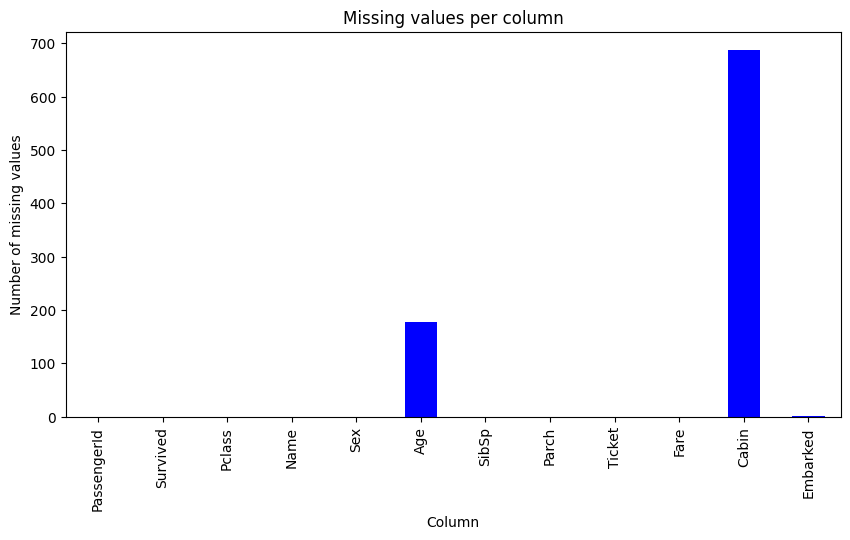

In [18]:
# 1. Create a bar chart showing how many missing values are in each column
missing = df.isnull().sum()

missing.plot(kind='bar', figsize=(10, 5), color='blue')
plt.title('Missing values per column')
plt.xlabel('Column')
plt.ylabel('Number of missing values')
plt.show()

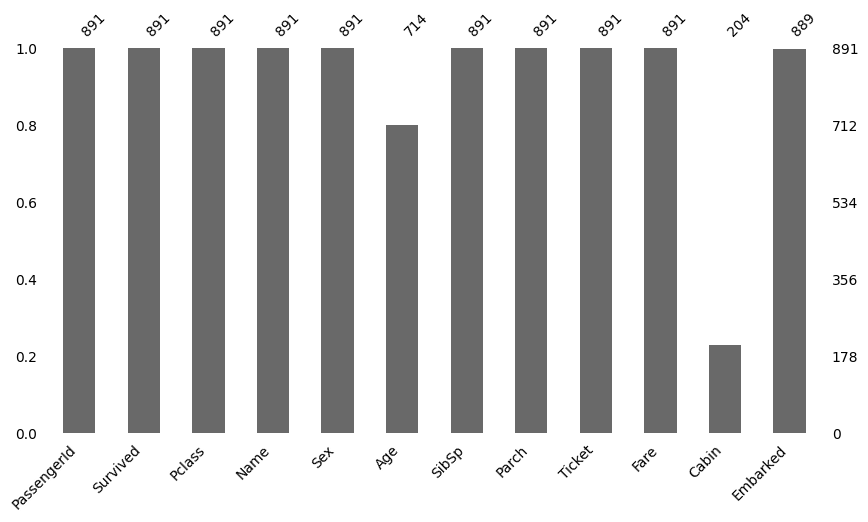

In [19]:
# Bonus: missingno library
import missingno as msno

msno.bar(df, figsize=(10, 5), fontsize=10)
plt.show()

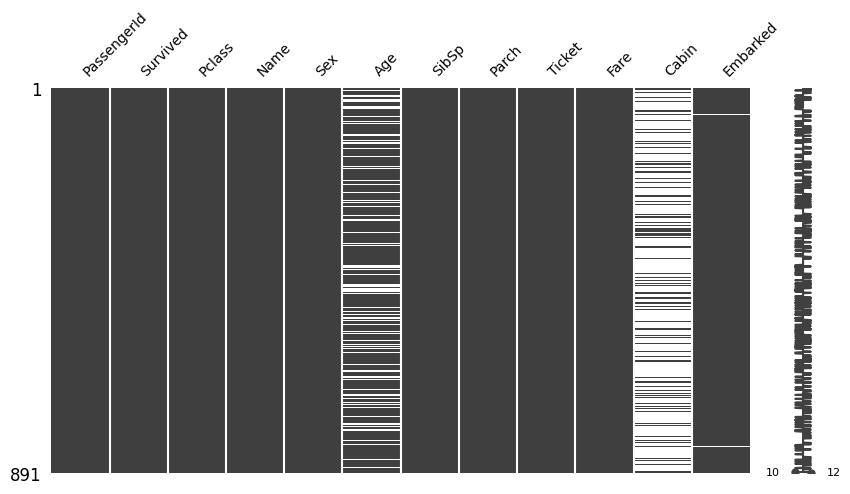

In [21]:
# msno.matrix - where are te missing values in the dataset
msno.matrix(df, figsize=(10, 5), fontsize=10)
plt.show()

In [22]:
# 2. Which column has the most NaN values? How many cells in that column are empty?
df.isnull().sum().sort_values(ascending=False)

,0
Cabin,687
Age,177
Embarked,2
PassengerId,0
Name,0
Pclass,0
Survived,0
Sex,0
Parch,0
SibSp,0


In [23]:
# 3. Delete all rows where Embarked is empty
df = df.dropna(subset=['Embarked'])

# Check the result
print(df['Embarked'].isnull().sum())
df.shape

0


(889, 12)

In [24]:
# 4. Fill all empty cabins with ¯\\(ツ)/¯
df['Cabin'] = df['Cabin'].fillna('¯\\(ツ)/¯')

df['Cabin'].value_counts().head()

,count
Cabin,
¯\(ツ)/¯,687
C23 C25 C27,4
G6,4
B96 B98,4
F33,3


# Step 3: Feature extraction

In [25]:
# 1. There are two columns that pertain to how many family members are on the boat
# for a given person. Create a new column called FamilyCount which will be the sum
# of those two columns.
df['FamilyCount'] = df['SibSp'] + df['Parch']

df[['SibSp', 'Parch', 'FamilyCount']].head()

,SibSp,Parch,FamilyCount
0,1,0,1
1,1,0,1
2,0,0,0
3,1,0,1
4,0,0,0


In [26]:
# 2. Reverends have a special title in their name. Create a column called IsReverend:
# 1 if they're a preacher, 0 if they're not.
df['IsReverend'] = df['Name'].str.contains('Rev.', regex=False).astype(int)

df[df['IsReverend'] == 1][['Name', 'IsReverend']]

,Name,IsReverend
149,"Byles, Rev. Thomas Roussel Davids",1
150,"Bateman, Rev. Robert James",1
249,"Carter, Rev. Ernest Courtenay",1
626,"Kirkland, Rev. Charles Leonard",1
848,"Harper, Rev. John",1
886,"Montvila, Rev. Juozas",1


In [27]:
# 3. In order to feed our training data into a classification algorithm, we need to
# convert our categories into 1's and 0's using pd.get_dummies
# Create 3 columns: Embarked_C, Embarked_Q and Embarked_S.

# We keep the original Embarked column because we need it in Step 4,
# so the dummies are created separately and joined back to df.
embarked_dummies = pd.get_dummies(df['Embarked'], prefix='Embarked', dtype=int)
df = pd.concat([df, embarked_dummies], axis=1)

df[['Embarked', 'Embarked_C', 'Embarked_Q', 'Embarked_S']].head()

,Embarked,Embarked_C,Embarked_Q,Embarked_S
0,S,0,0,1
1,C,1,0,0
2,S,0,0,1
3,S,0,0,1
4,S,0,0,1


In [28]:
# Do the same thing for Sex
sex_dummies = pd.get_dummies(df['Sex'], prefix='Sex', dtype=int)
df = pd.concat([df, sex_dummies], axis=1)

df[['Sex', 'Sex_female', 'Sex_male']].head()

,Sex,Sex_female,Sex_male
0,male,0,1
1,female,1,0
2,female,1,0
3,female,1,0
4,male,0,1


In [29]:
#I skipped the bonus here :)
#BONUS: Extract the title from everyone's name and create dummy columns


#Step 4: Exploratory analysis


In [30]:
# 1. What was the survival rate overall?
df['Survived'].mean()

np.float64(0.38245219347581555)

In [31]:
# 2. Which gender fared the worst? What was their survival rate?
df.groupby('Sex')['Survived'].mean()

,Survived
Sex,
female,0.740385
male,0.188908


In [32]:
# 3. What was the survival rate for each Pclass?
df.groupby('Pclass')['Survived'].mean()

,Survived
Pclass,
1,0.626168
2,0.472826
3,0.242363


In [35]:
# 4. Did any reverends survive? How many?


print('Reverends on board:', df['IsReverend'].sum())
print('Reverends who survived:', df[df['IsReverend'] == 1]['Survived'].sum())


df[df['IsReverend'] == 1][['Name', 'Survived']]

Reverends on board: 6
Reverends who survived: 0


,Name,Survived
149,"Byles, Rev. Thomas Roussel Davids",0
150,"Bateman, Rev. Robert James",0
249,"Carter, Rev. Ernest Courtenay",0
626,"Kirkland, Rev. Charles Leonard",0
848,"Harper, Rev. John",0
886,"Montvila, Rev. Juozas",0


In [36]:
# 5. What is the survival rate for cabins marked ¯\\(ツ)/¯
df[df['Cabin'] == '¯\\(ツ)/¯']['Survived'].mean()

np.float64(0.29985443959243085)

In [37]:
# For comparison: passengers with a known cabin
df[df['Cabin'] != '¯\\(ツ)/¯']['Survived'].mean()

np.float64(0.6633663366336634)

In [38]:
# 6. What is the survival rate for people whose Age is empty?
df[df['Age'].isnull()]['Survived'].mean()

np.float64(0.2937853107344633)

In [39]:
# 7. What is the survival rate for each port of embarkation?
df.groupby('Embarked')['Survived'].mean()

,Survived
Embarked,
C,0.553571
Q,0.389610
S,0.336957


In [40]:
# 8. What is the survival rate for children (under 12) in each Pclass?
children = df[df['Age'] < 12]

children.groupby('Pclass')['Survived'].agg(['mean', 'count'])

,mean,count
Pclass,,
1,0.750000,4
2,1.000000,17
3,0.404255,47


In [41]:
# 9. Did the captain of the ship survive? Is he on the list?
df[df['Name'].str.contains('Capt')][['Name', 'Age', 'Pclass', 'Survived']]

,Name,Age,Pclass,Survived
745,"Crosby, Capt. Edward Gifford",70.0,1,0


Answer: no :(

In [42]:
# 10. Of all the people that died, who had the most expensive ticket? How much did it cost?
died = df[df['Survived'] == 0]

died[died['Fare'] == died['Fare'].max()][['Name', 'Pclass', 'Ticket', 'Fare']]

,Name,Pclass,Ticket,Fare
27,"Fortune, Mr. Charles Alexander",1,19950,263.0
438,"Fortune, Mr. Mark",1,19950,263.0


In [43]:
# 11. Does having family on the boat help or hurt your chances of survival?
df.groupby('FamilyCount')['Survived'].agg(['mean', 'count'])

,mean,count
FamilyCount,,
0,0.300935,535
1,0.552795,161
2,0.578431,102
3,0.724138,29
4,0.200000,15
5,0.136364,22
6,0.333333,12
7,0.000000,6
10,0.000000,7


In [44]:
# Simple comparison: alone vs. with family
df['HasFamily'] = (df['FamilyCount'] > 0).astype(int)

df.groupby('HasFamily')['Survived'].mean()

,Survived
HasFamily,
0,0.300935
1,0.505650


# Step 5: Plotting

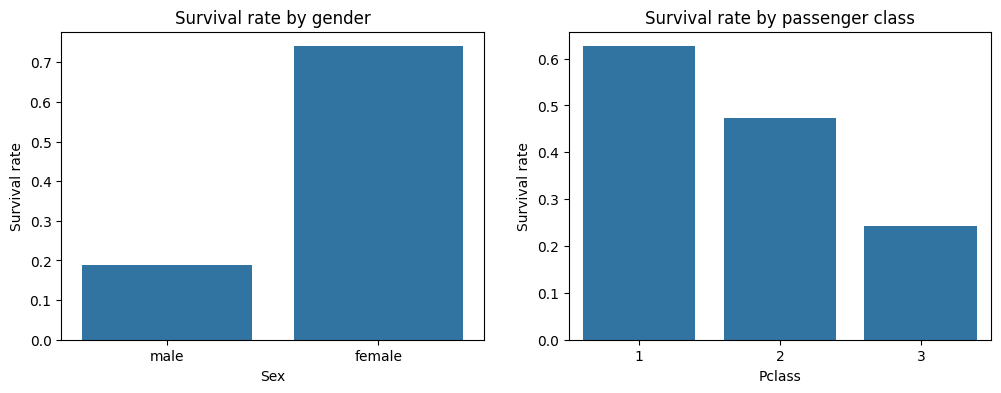

In [45]:
# Survival rate by gender and by passenger class
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

sns.barplot(data=df, x='Sex', y='Survived', ax=ax[0], errorbar=None)
ax[0].set_title('Survival rate by gender')
ax[0].set_ylabel('Survival rate')

sns.barplot(data=df, x='Pclass', y='Survived', ax=ax[1], errorbar=None)
ax[1].set_title('Survival rate by passenger class')
ax[1].set_ylabel('Survival rate')

plt.show()

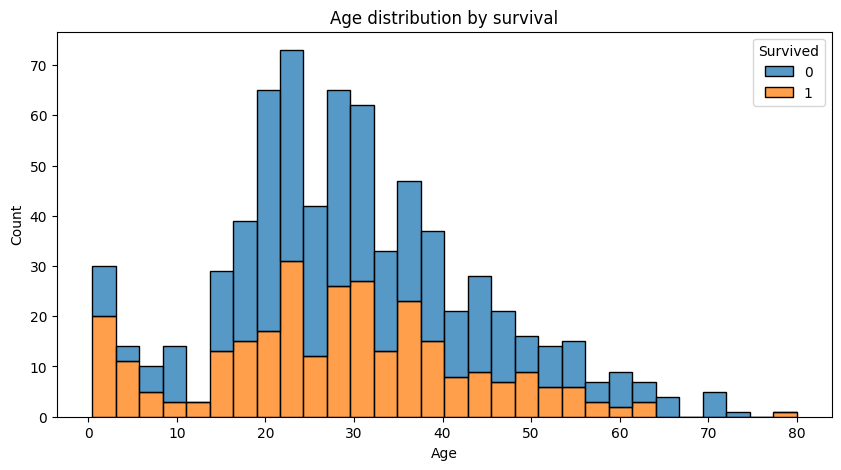

In [46]:
# Age distribution of survivors and non-survivors
plt.figure(figsize=(10, 5))
sns.histplot(data=df, x='Age', hue='Survived', bins=30, multiple='stack')
plt.title('Age distribution by survival')
plt.show()

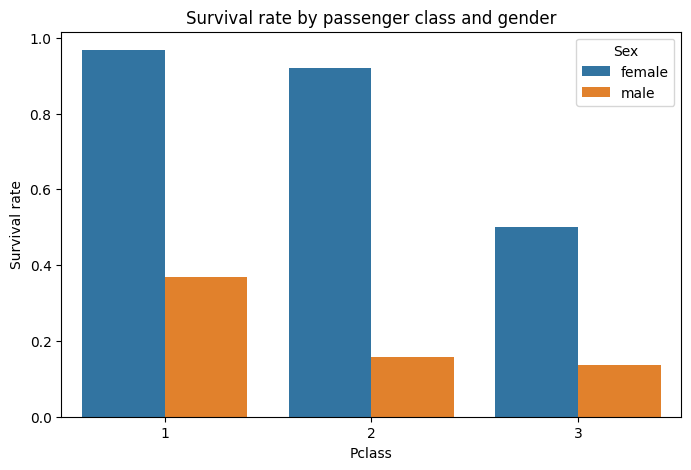

In [47]:
# Beneath the surface 1: gender AND class together
plt.figure(figsize=(8, 5))
sns.barplot(data=df, x='Pclass', y='Survived', hue='Sex', errorbar=None)
plt.title('Survival rate by passenger class and gender')
plt.ylabel('Survival rate')
plt.show()

Women in 1st and 2nd class almost all survived (97% and 92%), while women in 3rd class had only a 50% chance. For men, only 1st class made a real difference (37% against about 15%).

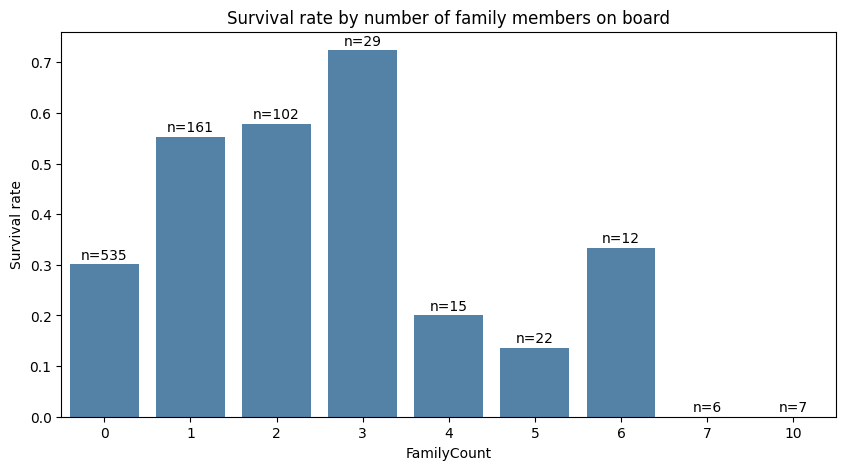

In [49]:
# family size
family = df.groupby('FamilyCount')['Survived'].agg(['mean', 'count']).reset_index()

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=family, x='FamilyCount', y='mean', color='steelblue', ax=ax)
for i, row in family.iterrows():
    ax.text(i, row['mean'] + 0.01, f"n={int(row['count'])}", ha='center')
ax.set_title('Survival rate by number of family members on board')
ax.set_ylabel('Survival rate')
plt.show()

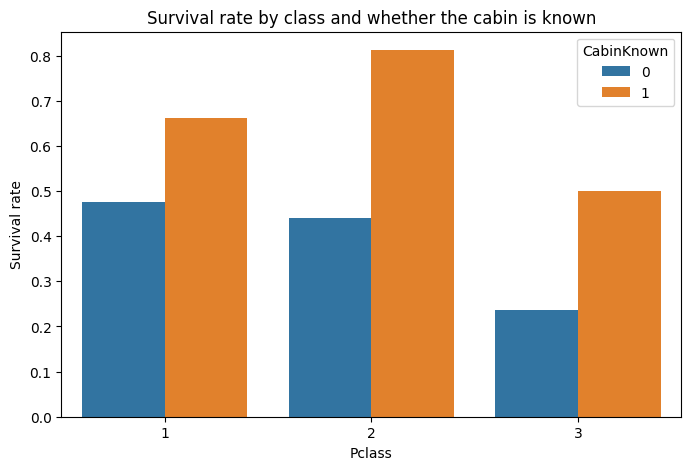

In [50]:
# known cabin vs. unknown cabin, within each class
df['CabinKnown'] = (df['Cabin'] != '¯\\(ツ)/¯').astype(int)

plt.figure(figsize=(8, 5))
sns.barplot(data=df, x='Pclass', y='Survived', hue='CabinKnown', errorbar=None)
plt.title('Survival rate by class and whether the cabin is known')
plt.ylabel('Survival rate')
plt.show()